# 05 · Price analysis — the eight questions

Every query lives in `sql/analysis_queries.sql`; this notebook runs them and adds a chart and a short reading of the result.

Three things to keep in mind while reading:

1. Prices are compared **only as ₹/kg, ₹/litre or ₹/unit**, and only within the same unit.
2. DoCA = official All-India averages, six dated points per commodity in this snapshot. Open Prices = crowd-sourced, sparse.
3. Nothing here is an inflation rate. CPI appears only as a separate benchmark at the end.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 45)

import analysis, viz
from config import DB_PATH

analysis.run_all()                       # refreshes the view and data/processed/analysis/*.csv
SQL = dict(analysis.blocks())
con = analysis.connect()                 # sqlite connection with SQRT available on every platform

def q(name):
    """Run one named block from sql/analysis_queries.sql."""
    return pd.read_sql(SQL[name], con)

## Q1 · Which products have increased most in price?

Latest official price (30 Sep 2026) against the official value one year and two years earlier.

In [2]:
q1 = q("q1a_commodity_price_change")
q1[["product_name", "category", "normalized_unit", "price_2y_ago", "price_1y_ago", "price_latest",
    "pct_change_1y", "pct_change_2y"]].head(12)

,product_name,category,normalized_unit,price_2y_ago,price_1y_ago,price_latest,pct_change_1y,pct_change_2y
0,Onion,Vegetables,INR/kg,53.82,27.08,53.86,98.89,0.07
1,Sugar,Sugar & Gur,INR/kg,44.80,46.54,56.02,20.37,25.04
2,Sunflower Oil (Packed),Edible Oils & Ghee,INR/kg,132.11,162.34,192.54,18.60,45.74
3,Coriander (Whole),"Tea, Salt & Spices",INR/kg,143.80,150.68,175.32,16.35,21.92
4,Palm Oil (Packed),Edible Oils & Ghee,INR/kg,114.85,132.66,153.72,15.88,33.84
5,Gur,Sugar & Gur,INR/kg,55.36,57.60,66.50,15.45,20.12
6,Soya Oil (Packed),Edible Oils & Ghee,INR/kg,129.33,146.38,166.80,13.95,28.97
7,Groundnut Oil (Packed),Edible Oils & Ghee,INR/kg,187.52,186.70,209.96,12.46,11.97
8,Tur/Arhar Dal,Pulses,INR/kg,163.64,114.87,125.81,9.52,-23.12
9,Red Chillies (Whole),"Tea, Salt & Spices",INR/kg,342.30,279.10,304.40,9.06,-11.07


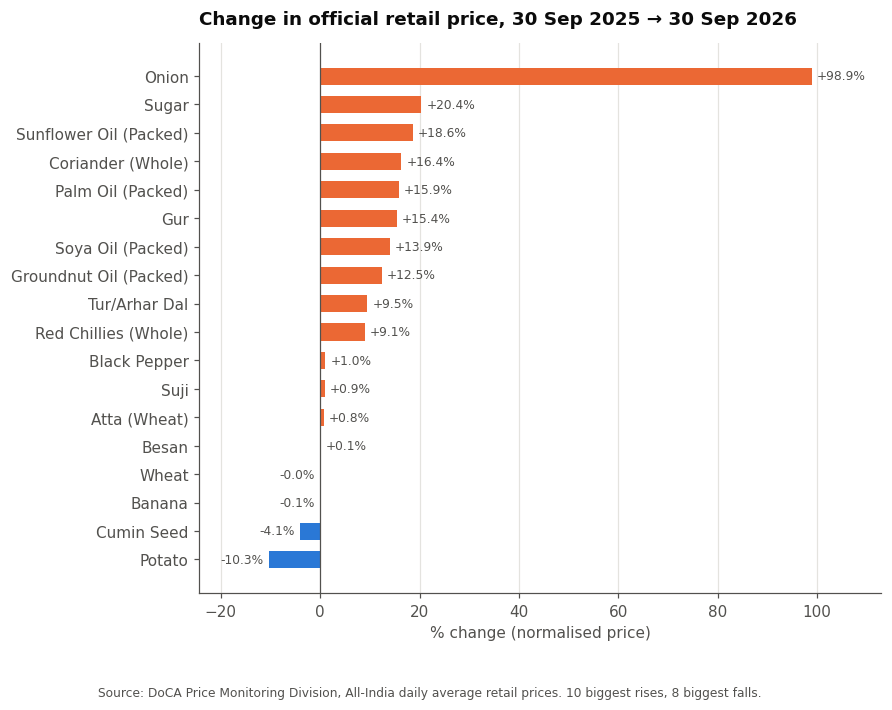

In [3]:
d = q1.dropna(subset=["pct_change_1y"]).sort_values("pct_change_1y")
d = pd.concat([d.head(8), d.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(d["product_name"], d["pct_change_1y"], color=viz.signed_colors(d["pct_change_1y"]), height=0.6)
ax.axvline(0, color=viz.MUTED, linewidth=0.8)
ax.set_xlim(d["pct_change_1y"].min() - 14, d["pct_change_1y"].max() + 14)
for y, v in enumerate(d["pct_change_1y"]):
    ax.text(v + (1 if v >= 0 else -1), y, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=viz.MUTED)
viz.style(ax, "Change in official retail price, 30 Sep 2025 → 30 Sep 2026", xlabel="% change (normalised price)",
          note="Source: DoCA Price Monitoring Division, All-India daily average retail prices. 10 biggest rises, 8 biggest falls.")
viz.save(fig, "05_q1_yoy_change"); plt.show()

**Reading it:** onion nearly doubled in a year (+99%), but it is back almost exactly where it was two years ago — that is a recovery from a crash, not a runaway rise. The steadier story is **edible oils**: sunflower +19% in a year and +46% over two years, with palm, soya, mustard and vanaspati all up 8–16% in the year. Sugar is up 20% year-on-year even after dropping 13% in the last month. Tur dal is the big two-year faller (−23%).

For branded products I can only look at barcodes someone happened to log twice:

In [4]:
q("q1b_product_repeat_observations")

,product_name,brand_name,pack_size_label,normalized_unit,first_date,first_city,first_norm_price,last_date,last_city,last_norm_price,pct_change,days_apart,comparability
0,Swing Coconut Water Drink,Paper Boat,1.2 l,INR/l,2025-03-02,Bengaluru,75.00,2025-09-23,Bengaluru,125.00,66.67,205,same city
1,Dove Cream Beauty Bar,Dove,100 g,INR/kg,2025-06-25,Madurai,580.00,2025-09-14,Madurai,600.00,3.45,81,same city
2,Dabur RED,Dabur,36 g,INR/kg,2025-04-20,Madurai,555.56,2025-06-28,Madurai,555.56,0.00,69,same city
3,Dark Fantasy Choco fills,ITC (Sunfeast),69 g,INR/kg,2026-08-03,Pedda Amiram,579.71,2026-09-02,Bengaluru,579.71,0.00,30,different city
4,Balaji Wafers Dum Bar,Balaji Wafers,19 g,INR/kg,2025-09-21,Kopargaon,263.16,2025-09-24,Kopargaon,263.16,0.00,3,same city
5,Date Crown Bumaan,Date Crown,500 g,INR/kg,2025-02-22,Hyderabad,190.00,2025-04-04,Hyderabad,178.00,-6.32,41,same city
6,Boost,Hindustan Unilever,550 g,INR/kg,2025-04-20,Madurai,434.55,2025-09-14,Madurai,403.64,-7.11,147,same city
7,Modern 100% Whole Wheat Bread,Modern,400 g,INR/kg,2025-01-30,Bengaluru,150.00,2025-03-09,Hyderabad,137.50,-8.33,38,different city
8,Mysore Sandal Soap,Karnataka Soaps & Detergents Ltd.,450 g,INR/kg,2025-04-20,Madurai,540.00,2025-06-28,Madurai,471.11,-12.76,69,same city
9,Matic Liquid,Surf Excel,1 l,INR/l,2025-05-15,Madurai,175.00,2025-06-25,Madurai,138.00,-21.14,41,same city


Eleven repeats, mostly in the same city. Useful as anecdotes (Paper Boat coconut water ₹75 → ₹125 per litre in Bengaluru over six months), not as a trend.

## Q2 · Which brands have the lowest normalised price?

Brands are ranked **inside one category and one unit** — ranking a water brand against a cola on ₹/litre would be meaningless across categories, and even inside "Beverages" it mixes product types, so treat this as indicative.

In [5]:
q2 = q("q2_brand_normalized_price")
q2[q2.sample_flag == "ok"]

,category,normalized_unit,brand_name,n_obs,n_products,avg_norm_price,min_norm_price,max_norm_price,rank_cheapest,brands_in_cat,sample_flag
2,Beverages,INR/kg,Hindustan Unilever,3,2,419.39,403.64,434.55,3,4,ok
12,Beverages,INR/l,Campa,3,3,89.61,40.00,162.16,9,16,ok
13,Beverages,INR/l,Paper Boat,4,3,115.00,75.00,160.00,10,16,ok
14,Beverages,INR/l,Coca-Cola,6,6,117.40,46.67,316.67,11,16,ok
25,"Biscuits, Bread & Bakery",INR/kg,Modern,3,2,136.57,122.22,150.00,6,28,ok
34,"Biscuits, Bread & Bakery",INR/kg,Britannia,9,9,311.20,95.00,1000.00,15,28,ok
73,"Chocolates, Sweets & Desserts",INR/kg,Amul,3,3,725.31,416.67,1333.33,8,20,ok
93,Dairy,INR/kg,Amul,3,3,478.18,454.55,505.00,5,10,ok
101,Dairy,INR/l,Amul,4,4,132.22,90.00,200.00,3,8,ok
117,"Nuts, Seeds & Dry Fruits",INR/kg,Date Crown,3,2,456.00,178.00,1000.00,3,7,ok


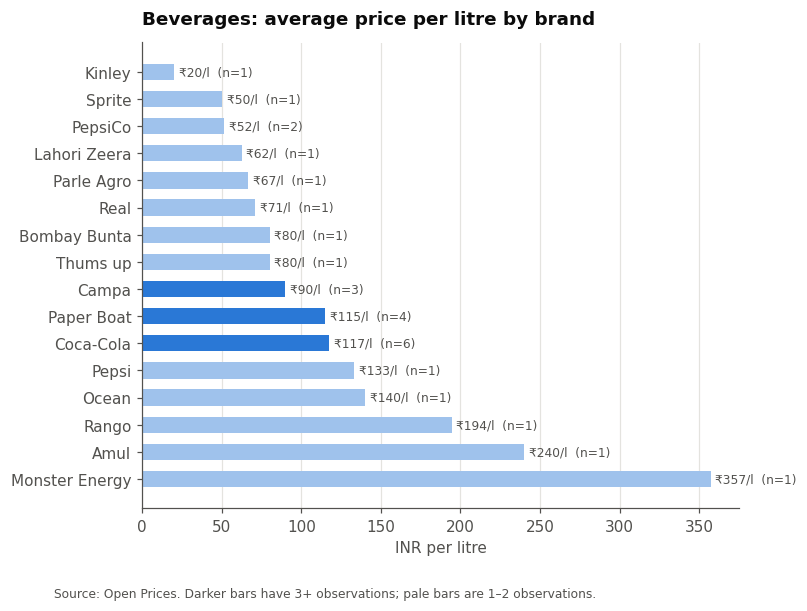

In [6]:
bev = q2[(q2.category == "Beverages") & (q2.normalized_unit == "INR/l")].sort_values("avg_norm_price", ascending=False)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(bev["brand_name"], bev["avg_norm_price"],
        color=[viz.BLUE if f == "ok" else "#9fc2ec" for f in bev["sample_flag"]], height=0.6)
for y, (v, n) in enumerate(zip(bev["avg_norm_price"], bev["n_obs"])):
    ax.text(v + 3, y, f"₹{v:.0f}/l  (n={n})", va="center", fontsize=8, color=viz.MUTED)
viz.style(ax, "Beverages: average price per litre by brand", xlabel="INR per litre",
          note="Source: Open Prices. Darker bars have 3+ observations; pale bars are 1–2 observations.")
viz.save(fig, "05_q2_beverage_brands"); plt.show()

**Reading it:** among drinks brands with at least three sightings, Campa (~₹90/l), Paper Boat (~₹115/l) and Coca-Cola (~₹117/l) are close together — Campa's cheaper positioning shows, but the gap is small for this sample; in bread & biscuits Modern (~₹137/kg) sits well below Britannia (~₹311/kg, whose mix includes premium biscuits). Most brands have only one or two observations, which is the honest limit of crowd-sourced data.

## Q3 · Which locations have the highest prices?

In [7]:
q("q3_location_price_index")

,method,city,state,region,n_obs,n_products,price_index
0,A_product_matched,Danapur,Bihar,East,1,1,117.8
1,A_product_matched,Bengaluru,Karnataka,South,2,2,102.2
2,A_product_matched,Irinjalakuda,Kerala,South,1,1,100.0
3,A_product_matched,Pedda Amiram,Andhra Pradesh,South,1,1,100.0
4,A_product_matched,Thrissur,Kerala,South,1,1,100.0
5,A_product_matched,Hyderabad,Telangana,South,1,1,95.7
6,A_product_matched,Dholi,Bihar,East,1,1,82.2
7,B_category_relative,Pune,Maharashtra,West,9,9,249.8
8,B_category_relative,Kochi (Ernakulam),Kerala,South,10,10,134.7
9,B_category_relative,Dispur,Assam,North-East,8,8,117.5


**Reading it:** I can't answer this one robustly yet, and I'd rather say so. The strict method (same barcode seen in 2+ cities) covers only seven cities with one or two observations each. The looser category-relative index puts Pune and Kochi on top and Delhi and Mumbai at the bottom, but it mostly reflects *what* contributors in each city bought. The proper source — DoCA's centre-wise prices — is CAPTCHA-protected, so it is out of scope by design.

## Q4 · Which categories show the highest price volatility?

Coefficient of variation (standard deviation ÷ mean) across each commodity's six official points over two years, averaged by category.

In [8]:
q4 = q("q4_category_volatility")
q4

,category,n_commodities,avg_cv_pct,max_cv_pct,most_volatile_commodity,avg_high_low_range_pct,avg_max_step_change_pct
0,Vegetables,6,16.18,28.69,Onion,62.0,38.6
1,Sugar & Gur,2,10.92,13.58,Sugar,32.5,27.9
2,Edible Oils & Ghee,7,8.30,12.76,Sunflower Oil (Packed),28.2,15.3
3,"Tea, Salt & Spices",7,5.87,11.79,Turmeric (Powder),17.9,12.2
4,Pulses,7,3.55,12.32,Tur/Arhar Dal,11.5,8.8
5,"Milk, Dairy & Eggs",3,2.41,3.66,Eggs,6.1,4.4
6,Cereals & Flours,8,1.89,3.46,Rice,5.2,3.5
7,Fruits,1,1.07,1.07,Banana,2.9,2.3


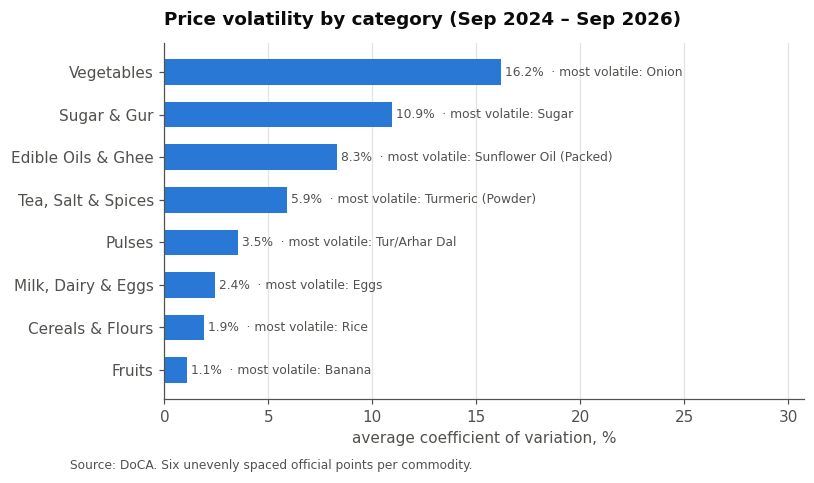

In [9]:
d = q4.sort_values("avg_cv_pct")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(d["category"], d["avg_cv_pct"], color=viz.BLUE, height=0.6)
for y, (v, top) in enumerate(zip(d["avg_cv_pct"], d["most_volatile_commodity"])):
    ax.text(v + 0.2, y, f"{v:.1f}%  · most volatile: {top}", va="center", fontsize=8, color=viz.MUTED)
ax.set_xlim(0, d["avg_cv_pct"].max() * 1.9)
viz.style(ax, "Price volatility by category (Sep 2024 – Sep 2026)", xlabel="average coefficient of variation, %",
          note="Source: DoCA. Six unevenly spaced official points per commodity.")
viz.save(fig, "05_q4_volatility"); plt.show()

**Reading it:** vegetables are in a league of their own (onion, potato, tomato), then sugar & gur and edible oils. Cereals, flours and dairy barely move. That ordering matches what you'd expect from perishability and import exposure, which is a good sanity check on the pipeline.

## Q5 · Which products frequently become unavailable?

In [10]:
q5 = q("q5_unavailability")
q5[(q5.not_reported_gaps > 0) | (q5.before_series_start > 0)]

,product_name,category,price_type,points_checked,reported,not_reported_gaps,before_series_start,gap_rate_pct,first_reported_date
0,Broken Rice,Cereals & Flours,retail,6,3,0,3,0.0,2026-08-30
1,Garlic,Vegetables,retail,6,4,0,2,0.0,2026-03-30
2,Ginger,Vegetables,retail,6,4,0,2,0.0,2026-03-30


**Reading it:** none. Every live DoCA series reported a price on every captured date. The only blanks are before Broken Rice, Ginger and Garlic were added to monitoring. No legitimate source here records shelf stock-outs, so "availability" in this project means *price reported by the source* — a limitation stated in the docs.

## Q6 · How much does the same product vary between locations?

In [11]:
q("q6_same_product_across_locations")

,product_code,product_name,brand_name,pack_size_label,normalized_unit,n_obs,n_cities,cities,min_pack_price,max_pack_price,max_vs_min_pct,first_date,last_date
0,8906043190451,Soan Papdi,Pramod Multifold pvt ltd,400 g,INR/kg,2,2,"Danapur,Dholi",125.0,179.0,43.2,2026-04-09,2026-04-10
1,8904043551548,Modern 100% Whole Wheat Bread,Modern,400 g,INR/kg,2,2,"Bengaluru,Hyderabad",55.0,60.0,9.1,2025-01-30,2025-03-09
2,8901725118921,Tedha Medha,ITC (Bingo),NaN,NaN,2,2,"Pune,Hyderabad",20.0,20.0,0.0,2025-06-16,2025-06-17
3,8901725015275,Dark Fantasy Choco fills,ITC (Sunfeast),69 g,INR/kg,2,2,"Pedda Amiram,Bengaluru",40.0,40.0,0.0,2026-08-03,2026-09-02
4,8901058017687,Maggi,Nestlé (Maggi),NaN,NaN,2,2,"Hyderabad,Narsinghpur",15.0,15.0,0.0,2025-08-15,2026-04-22
5,0986614900106,OK Hyderabadi Veg Biriyani,Spot On,25 g,INR/kg,2,2,"Thrissur,Irinjalakuda",5.0,5.0,0.0,2025-09-11,2025-09-11


Only six barcodes were seen in more than one city. Four had identical prices (MRP-printed snacks and noodles); Soan Papdi 400 g varied 43% between two towns in Bihar on consecutive days.

A related question the official data *can* answer: how far apart are wholesale and retail for the same commodity on the same day?

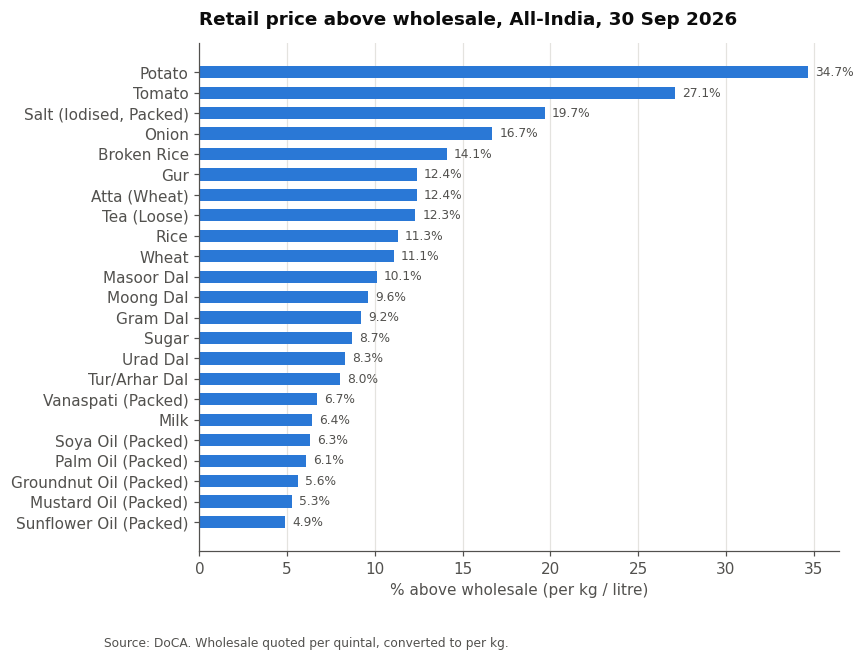

In [12]:
q6b = q("q6b_wholesale_to_retail_spread").sort_values("retail_markup_over_wholesale_pct")
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(q6b["product_name"], q6b["retail_markup_over_wholesale_pct"], color=viz.BLUE, height=0.6)
for y, v in enumerate(q6b["retail_markup_over_wholesale_pct"]):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", fontsize=8, color=viz.MUTED)
viz.style(ax, "Retail price above wholesale, All-India, 30 Sep 2026", xlabel="% above wholesale (per kg / litre)",
          note="Source: DoCA. Wholesale quoted per quintal, converted to per kg.")
viz.save(fig, "05_q6_retail_vs_wholesale"); plt.show()

**Reading it:** fresh vegetables carry the widest gap (potato +35%, tomato +27%), packed edible oils the narrowest (~5–7%). Perishability and handling costs show up clearly.

## Q7 · How do discounts affect effective price?

In [13]:
q7 = q("q7_discount_effect")
q7

,category_group,category,n_obs,n_discounted,pct_obs_discounted,avg_discount_pct_when_discounted,total_rupees_saved,avg_norm_list_price_disc_items,avg_norm_effective_price_disc_items
0,ALL,ALL,375,77,20.5,25.5,4245.71,NaN,NaN
1,Packaged Food,"Biscuits, Bread & Bakery",55,10,18.2,24.5,219.00,331.85,255.11
2,Packaged Food,Beverages,38,7,18.4,19.3,201.00,211.81,177.72
3,Packaged Food,Other Packaged Food,38,7,18.4,27.9,172.00,392.00,299.00
4,Packaged Food,"Chocolates, Sweets & Desserts",30,1,3.3,19.4,7.00,600.00,483.33
5,Personal Care,Personal Hygiene & Care,29,6,20.7,22.3,229.00,1490.83,960.42
6,Groceries,"Staples, Spices & Hot Beverages",28,13,46.4,21.0,402.70,477.52,409.33
7,Packaged Food,Dairy,26,1,3.8,33.3,5.00,83.33,55.56
8,Packaged Food,"Breakfast, Noodles & Ready Meals",25,5,20.0,35.0,612.00,443.75,276.08
9,Packaged Food,Salty Snacks & Namkeen,22,1,4.5,1.2,1.00,566.67,560.00


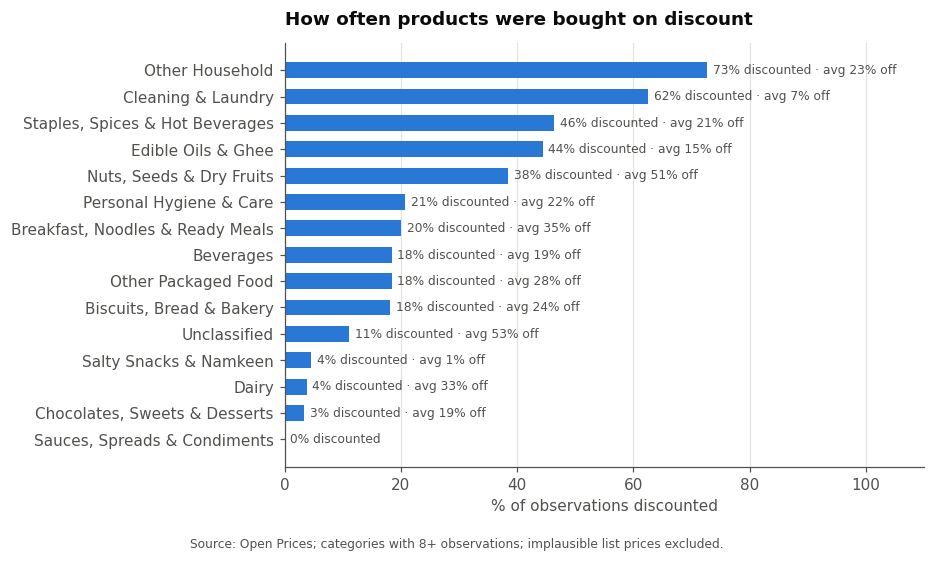

In [14]:
d = q7[(q7.category != "ALL") & (q7.n_obs >= 8)].sort_values("pct_obs_discounted")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(d["category"], d["pct_obs_discounted"], color=viz.BLUE, height=0.6)
for y, (v, a) in enumerate(zip(d["pct_obs_discounted"], d["avg_discount_pct_when_discounted"])):
    label = f"{v:.0f}% discounted" + (f" · avg {a:.0f}% off" if pd.notna(a) else "")
    ax.text(v + 1, y, label, va="center", fontsize=8, color=viz.MUTED)
ax.set_xlim(0, 110)
viz.style(ax, "How often products were bought on discount", xlabel="% of observations discounted",
          note="Source: Open Prices; categories with 8+ observations; implausible list prices excluded.")
viz.save(fig, "05_q7_discounts"); plt.show()

**Reading it:** about one in five observations was discounted, by ~25% on average when it was. Discounts cluster in household/cleaning products and staples (46% of staples observations), and are rare for chocolates, snacks and dairy — products that mostly sell at printed MRP. For discounted staples the effective price averaged ₹409/kg against a list ₹478/kg.

## Q8 · What is the month-over-month price change?

Official value on 30 Aug 2026 against 30 Sep 2026.

In [15]:
q8 = q("q8_mom_change")
q8b = q("q8b_mom_category")
q8b

,category,n_commodities,avg_mom_pct,min_mom_pct,max_mom_pct
0,Vegetables,6,5.05,-4.28,11.49
1,Pulses,7,2.06,0.77,3.35
2,"Tea, Salt & Spices",7,2.04,-0.71,4.02
3,Fruits,1,1.78,1.78,1.78
4,Cereals & Flours,9,1.69,-0.73,5.79
5,Edible Oils & Ghee,7,1.19,0.19,1.70
6,"Milk, Dairy & Eggs",3,1.10,0.25,2.32
7,Sugar & Gur,2,-7.03,-12.78,-1.28


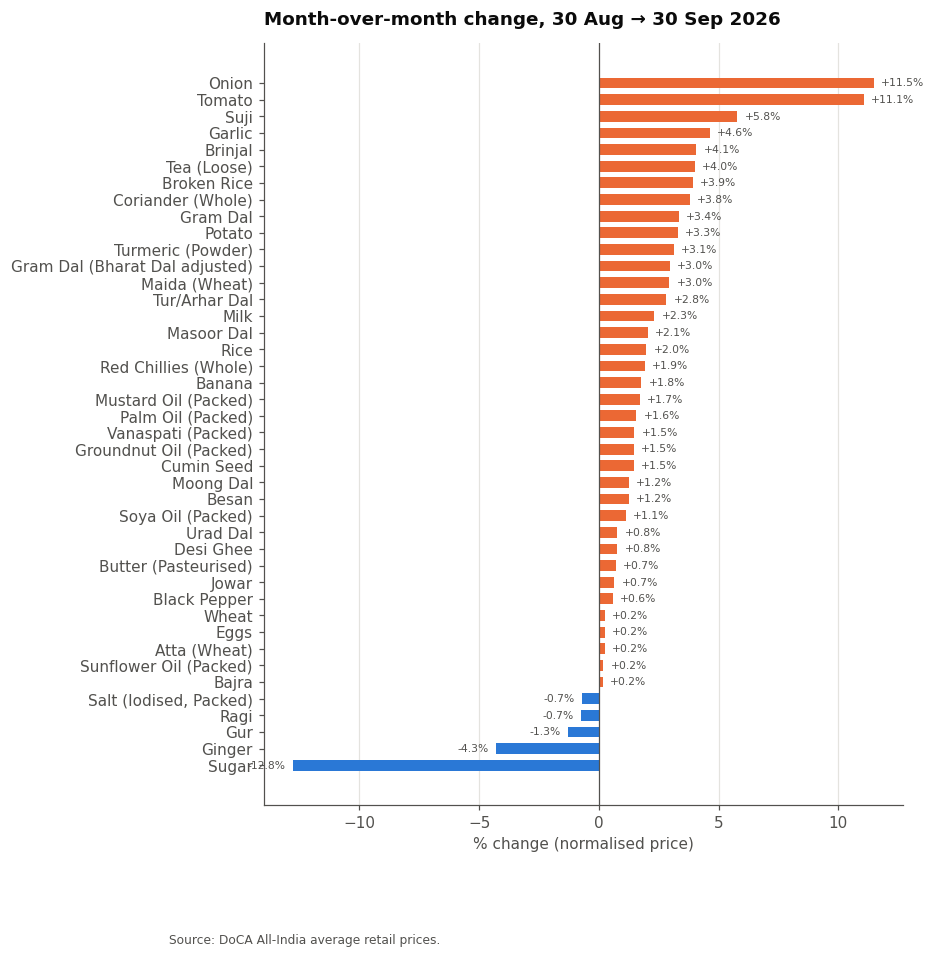

In [16]:
d = q8.sort_values("mom_pct")
fig, ax = plt.subplots(figsize=(7.5, 9))
ax.barh(d["product_name"], d["mom_pct"], color=viz.signed_colors(d["mom_pct"]), height=0.65)
ax.axvline(0, color=viz.MUTED, linewidth=0.8)
for y, v in enumerate(d["mom_pct"]):
    ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right",
            fontsize=7, color=viz.MUTED)
viz.style(ax, "Month-over-month change, 30 Aug → 30 Sep 2026", xlabel="% change (normalised price)",
          note="Source: DoCA All-India average retail prices.")
viz.save(fig, "05_q8_mom"); plt.show()

**Reading it:** vegetables led the month (+5% on average; onion and tomato both about +11%). Most staples crept up 1–2%. Sugar was the clear exception at −13% — even so it is still 20% above a year ago.

As the extractor runs daily, this question becomes a proper monthly series; for now it is one official month-on-month step.

## Benchmark · DoCA prices vs MoSPI CPI

Different methodologies — an average price versus a weighted index — so I put them **side by side**, never on the same scale in one series. Change from Sep 2024 to Sep 2025 in DoCA, against the CPI item's year-on-year inflation for Sep 2025.

In [17]:
b = q("bench_doca_vs_cpi_yoy")
b.head(10)

,doca_commodity,cpi_item,match_quality,doca_price_change_pct,cpi_item_yoy_pct_sep2025,gap_pp
0,Potato,Potato,close,-31.14,-37.34,6.20
1,Coriander (Whole),Dhania (gm),close,4.78,0.05,4.73
2,Desi Ghee,Ghee,close,6.93,3.73,3.20
3,Groundnut Oil (Packed),Groundnut Oil,close,-0.44,-3.51,3.07
4,Sunflower Oil (Packed),"Refined Oil [sunflower, Soyabean, Saffola...",approximate,22.88,20.20,2.68
5,Banana,Banana (no.),close,-0.50,-2.57,2.07
6,Vanaspati (Packed),"Vanaspati, Margarine",close,20.26,18.86,1.40
7,Urad Dal,Urd,close,-8.14,-9.40,1.26
8,Mustard Oil (Packed),Mustard Oil,close,22.23,20.97,1.26
9,Gram Dal,Gram: Split,close,-7.31,-8.50,1.19


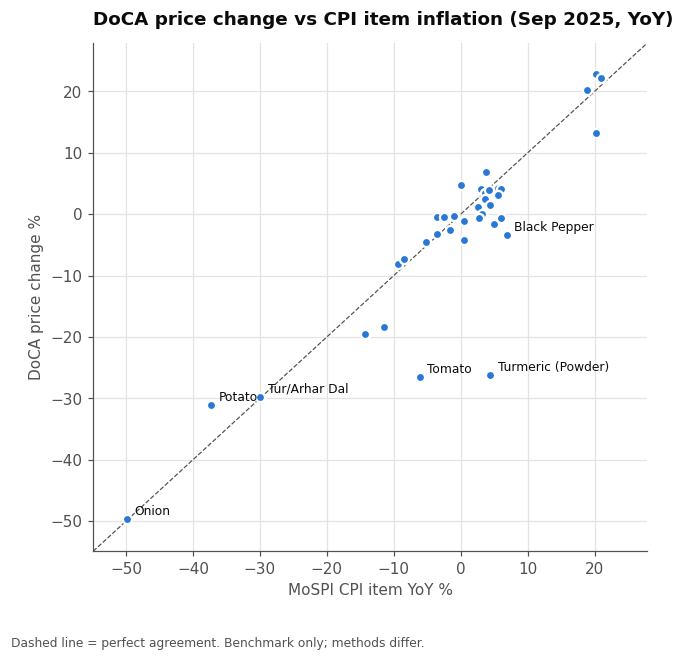

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(b["cpi_item_yoy_pct_sep2025"], b["doca_price_change_pct"], s=36, color=viz.BLUE,
           edgecolor="white", linewidth=1.5, zorder=3)
lim = [min(b.min(numeric_only=True)[["doca_price_change_pct", "cpi_item_yoy_pct_sep2025"]]) - 5,
       max(b.max(numeric_only=True)[["doca_price_change_pct", "cpi_item_yoy_pct_sep2025"]]) + 5]
ax.plot(lim, lim, color=viz.MUTED, linewidth=0.8, linestyle="--", zorder=2)
for _, r in b[b["doca_price_change_pct"].abs().gt(25) | b["gap_pp"].abs().gt(9)].iterrows():
    ax.annotate(r["doca_commodity"], (r["cpi_item_yoy_pct_sep2025"], r["doca_price_change_pct"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8, color=viz.INK)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(color=viz.GRID, linewidth=0.8)
viz.style(ax, "DoCA price change vs CPI item inflation (Sep 2025, YoY)",
          xlabel="MoSPI CPI item YoY %", ylabel="DoCA price change %",
          note="Dashed line = perfect agreement. Benchmark only; methods differ.")
viz.save(fig, "05_benchmark_doca_vs_cpi"); plt.show()

**Reading it:** for most items the two agree well — 22 of 37 are within 3 percentage points (onion −49.7% vs −49.9%, tur −29.8% vs −30.0%, mustard oil +22.2% vs +21.0%). The clear disagreements are **turmeric** (DoCA −26% vs CPI +4%), **tomato** (−27% vs −6%) and **black pepper** (−3% vs +7%). Two likely reasons: DoCA is a single day's price while CPI averages the whole month (tomato swings a lot within a month), and the items aren't defined identically (DoCA quotes turmeric *powder* per 50 g). Agreement on most items is a useful check on my normalisation and dates — but it doesn't make this project an inflation measure.

## Q9 · Price-spike monitor (switches on as daily history builds up)

This is what turns the project from a one-off snapshot into a monitoring tool. For each commodity I look at its **day-to-day** price changes (gaps of 1–4 days count, to allow for weekends). A day is a **spike** when its change is more than **2 standard deviations above that commodity's normal daily change** (z > 2); a sharp drop is z < −2. Each commodity needs at least 10 daily steps before it is judged, so the monitor doesn't fire on noise.

The 6 look-back points (a week, a month, a year apart) are not daily steps, so right now every commodity is still collecting:

In [19]:
depth = q("q9_history_depth")
print(depth["spike_detection_status"].value_counts().to_string())
depth.head(10)

spike_detection_status
collecting    42


,product_name,dated_points,daily_steps,first_date,last_date,spike_detection_status
0,Atta (Wheat),6,0,2024-09-30,2026-09-30,collecting
1,Bajra,6,0,2024-09-30,2026-09-30,collecting
2,Banana,6,0,2024-09-30,2026-09-30,collecting
3,Besan,6,0,2024-09-30,2026-09-30,collecting
4,Black Pepper,6,0,2024-09-30,2026-09-30,collecting
5,Brinjal,6,0,2024-09-30,2026-09-30,collecting
6,Broken Rice,3,0,2026-08-30,2026-09-30,collecting
7,Butter (Pasteurised),6,0,2024-09-30,2026-09-30,collecting
8,Coriander (Whole),6,0,2024-09-30,2026-09-30,collecting
9,Cumin Seed,6,0,2024-09-30,2026-09-30,collecting


In [20]:
spikes = q("q9_price_spikes")
this_week = spikes[spikes["is_this_week"] == 1]
if spikes.empty:
    print("No spikes yet - each commodity needs 10+ daily price steps. Run the daily collection for 2-3 weeks.")
else:
    display(this_week if not this_week.empty else spikes.head(15))

No spikes yet - each commodity needs 10+ daily price steps. Run the daily collection for 2-3 weeks.


I tested the logic on a synthetic series (25 days of ±0.4% noise with one 8% jump and a year-old look-back point mixed in): it flagged only the jump (z ≈ 4.3) and ignored the look-back point. The same table feeds the Power BI alert page (`powerbi/data/price_spikes.csv`).

## Summary

| Question | Answer (snapshot of 1 Oct 2026) | Confidence |
|---|---|---|
| Q1 biggest increases | Onion +99% YoY (recovery), sugar +20%, edible oils +8–19% YoY / up to +46% over 2 yrs | high (official) |
| Q2 cheapest brands | Within-category rankings available; most brands have <3 sightings | low–medium |
| Q3 priciest locations | Not answerable robustly with legitimate data | low |
| Q4 most volatile | Vegetables ≫ sugar & gur > edible oils > spices > pulses > dairy > cereals | high |
| Q5 unavailability | No gaps in live DoCA series; stock-outs not measurable | — |
| Q6 same product across places | 6 barcodes only; retail vs wholesale gap 5% (oils) – 35% (potato) | low / high |
| Q7 discounts | ~1 in 5 observations discounted, ~25% off on average | medium |
| Q8 month-on-month | Vegetables +5%, staples +1–2%, sugar −13% | high |
| Q9 spike monitor | Built and tested; waiting for 10+ daily points per commodity | — |

Charts are saved in `reports/figures/`, query results in `data/processed/analysis/`.

In [21]:
con.close()